# Занятие 4. От регрессии к классификации

Предскажем класс квартиры по её характеристикам.
Используем готовый файл `data/data.csv`: категории уже закодированы, целевая переменная — `above_market`.

**Классы:** `1` — выше рынка; `0` — ниже либо в рамках рынка.
Ценовые столбцы исключены из датасета заранее, чтобы они не раскрывали правильный ответ.

## Оглавление

1. [Потери, кросс-валидация и переобучение](#review)
2. [Масштабирование: зачем и как](#scaling)
3. [Библиотеки и пример преобразования чисел](#imports)
4. [Данные и целевая переменная](#data)
5. [Признаки и ответ](#features)
6. [Train и test](#split)
7. [Простое исходное решение](#baseline)
8. [Логистическая регрессия: формула, обучение, log loss](#model)
9. [Кросс-валидация на train](#cv)
10. [Финальная проверка и метрики](#metrics)
11. [Вероятность и порог](#threshold)
12. [Практические задания и выводы](#tasks)

<a id="review"></a>
## 1. Напоминание: потери, кросс-валидация и переобучение

### 1.1. Потери и метрики: разные роли

| Понятие | На какой вопрос отвечает? | Пример |
|---|---|---|
| Функция потерь | Как изменить веса во время обучения? | MSE в линейной регрессии, log loss в логистической |
| Метрика | Насколько хорош готовый прогноз? | RMSE, accuracy, precision, recall, F1 |

Одно вычисление может выполнять обе роли: MSE можно минимизировать на train, затем считать на проверке.
В нашей классификации **обучаем по log loss**, а классы оцениваем по accuracy, precision, recall и F1.

### 1.2. Кросс-валидация: несколько репетиций проверки

Одно случайное разбиение может оказаться удачным или неудачным. Чтобы не судить по одной попытке:

1. Сначала откладываем финальный test.
2. Оставшийся **train** делим, например, на пять блоков.
3. Обучаем модель на четырёх, проверяем на пятом.
4. Меняем проверочный блок и **обучаем заново**. Всего пять обучений.
5. Смотрим среднее качество и разброс пяти результатов.

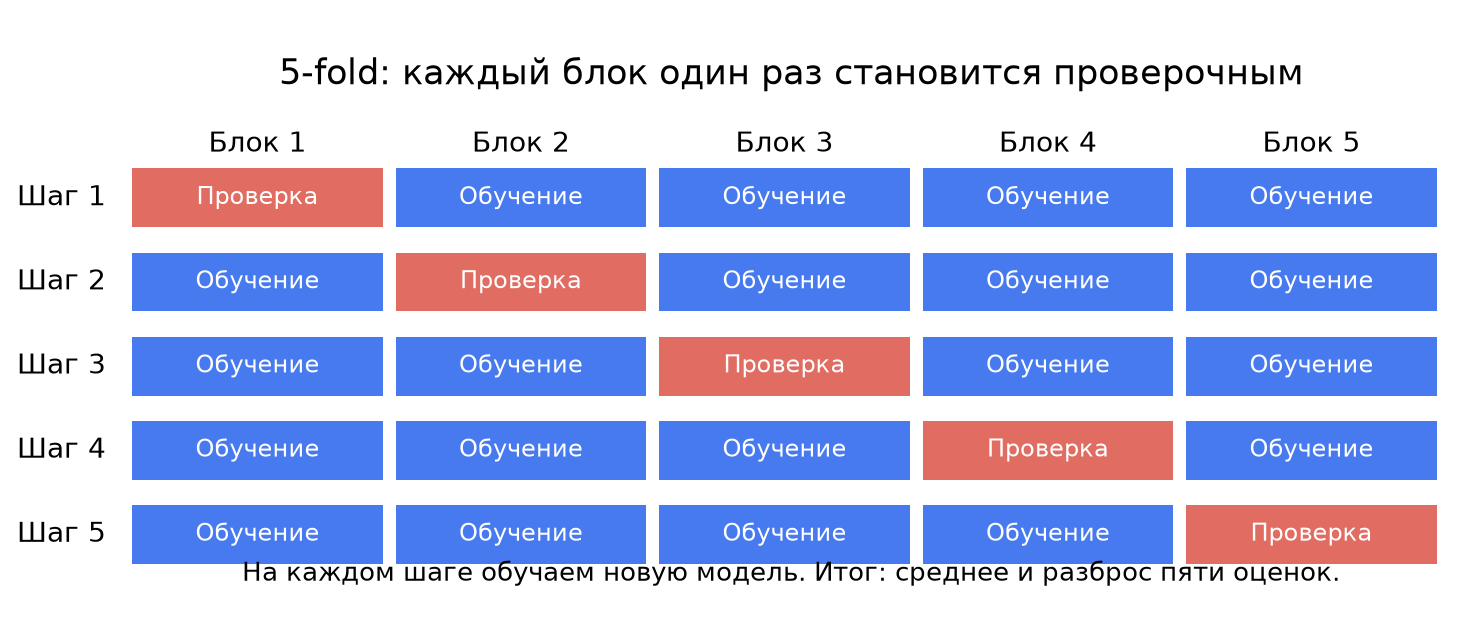

На каждой строке схемы — новое обучение. Один блок проверочный, остальные обучающие.
**Test в этой схеме не участвует.** После выбора решения он служит последней проверкой.

Пример пяти RMSE: `1, 2, 2, 2, 3`. Среднее — `2`, стандартное отклонение — примерно `0,632`.
Для классификации аналогично усредняем F1 или accuracy. Сильный разброс означает нестабильность оценки, но сам по себе не доказывает переобучение.

Подготовку тоже обучаем заново: среднее для scaler нельзя брать из проверочного блока.
В практике это обеспечит `Pipeline`. Для повторов одной квартиры нужны группы, для прогноза будущего — разбиение по времени.

### 1.3. Недообучение и переобучение

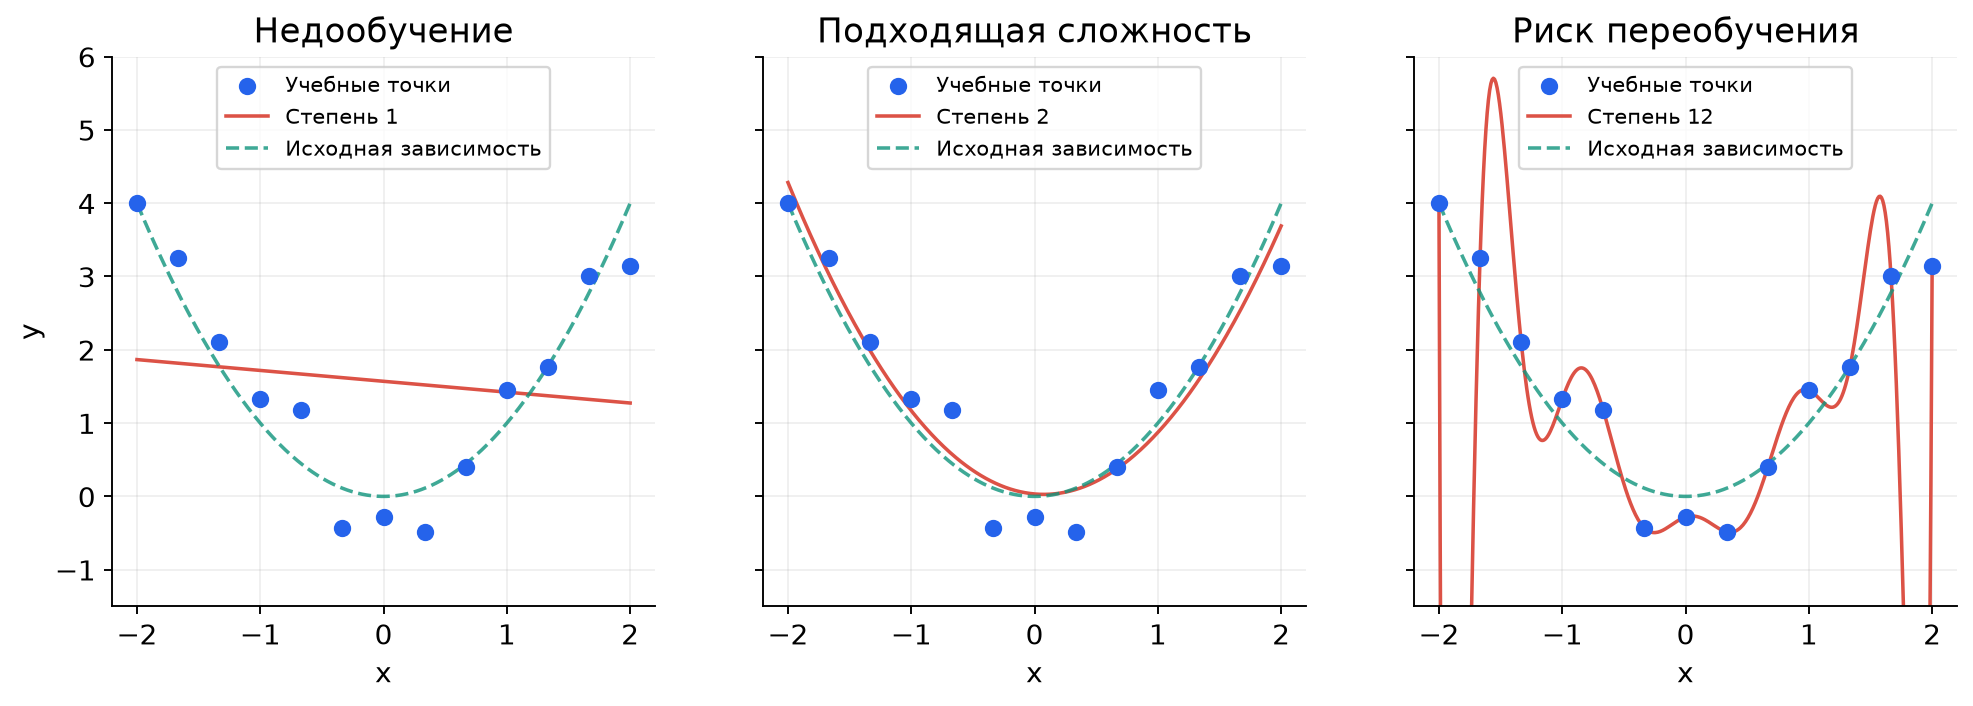

- **Слева, недообучение:** прямая слишком проста для изгиба. Ошибки велики и на train, и на проверке.
- **В середине:** модель улавливает общую зависимость и переносит её на новые точки.
- **Справа, переобучение:** гибкая кривая подстраивается под отдельные учебные точки и колеблется между ними. Train может быть отличным, а проверка — заметно хуже.

В классификации смотрим на тот же разрыв, но помним направление метрики: **RMSE меньше — лучше, F1 больше — лучше**.
Например, F1 train `0,99`, validation `0,60` — повод проверить переобучение; F1 `0,55` и `0,54` — возможное недообучение.
Большие веса и разброс по блокам отдельно не доказывают причину. Проверяем также утечку, разбиение и различия данных.


<a id="scaling"></a>
## 2. Масштабирование: зачем это нужно на практике

Площадь бывает `30–90`, число комнат — `1–4`. Это разные единицы и диапазоны.
**Масштабирование переписывает каждый столбец в более удобной шкале, сохраняя порядок значений.** Квартира и её класс не меняются.

### 2.1. Min-Max: превращаем обучающий диапазон в 0–1

$$x' = \frac{x-x_{\min,train}}{x_{\max,train}-x_{\min,train}}.$$

Если площади train — `30, 45, 60, 75, 90`, вычитаем 30 и делим на 60:

| Площадь | Считаем | Результат |
|---:|---|---:|
| 30 | (30 − 30) / 60 | 0 |
| 45 | (45 − 30) / 60 | 0,25 |
| 60 | (60 − 30) / 60 | 0,5 |
| 75 | (75 − 30) / 60 | 0,75 |
| 90 | (90 − 30) / 60 | 1 |

У комнат `1–4` своя шкала: `1 → 0`, `2 → 0,333`, `3 → 0,667`, `4 → 1`.
Новая площадь `120 → 1,5`: новый объект может выйти за обучающий диапазон.

### 2.2. Standard: показываем отклонение от среднего

$$x' = \frac{x-\bar{x}_{train}}{\sigma_{train}}.$$

У тех же площадей среднее `60`, стандартное отклонение примерно `21,21`:

| Площадь | Standard, примерно | Смысл |
|---:|---:|---|
| 30 | −1,414 | Ниже среднего на 1,414 стандартного отклонения |
| 45 | −0,707 | Ниже среднего |
| 60 | 0 | Ровно среднее |
| 75 | +0,707 | Выше среднего |
| 90 | +1,414 | Выше среднего на 1,414 стандартного отклонения |

**Вывод:** в логистической регрессии масштабирование переводит количественные признаки в сопоставимые шкалы и помогает численному подбору весов. Оно не создаёт новые сведения, не гарантирует рост качества, не убирает выбросы и не делает распределение нормальным.

Статистики считаем **только на train**; к test применяем те же числа. Внутри кросс-валидации scaler учится только на обучающих блоках. Для константных столбцов библиотеки используют специальную обработку, чтобы не делить на ноль.


<a id="imports"></a>
## 3. Библиотеки

`pandas` работает с таблицей, `numpy` — с вычислениями, `matplotlib` — с графиками.
Из `scikit-learn` возьмём подготовку, модели и метрики. Запускайте ячейки сверху вниз.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, roc_auc_score, ConfusionMatrixDisplay,
)

SEED = 42

### Маленький пример масштабирования

Это отдельная учебная таблица, а не подготовка всей выборки. Оба scaler обучаются на пяти площадях;
новую площадь `120` только преобразуем. В StandardScaler стандартное отклонение считается с делением на `n`.

In [ ]:
area_train = pd.DataFrame({"Площадь": [30, 45, 60, 75, 90]})
area_new = pd.DataFrame({"Площадь": [120]})

minmax = MinMaxScaler().fit(area_train)
standard = StandardScaler().fit(area_train)

scaling_example = area_train.copy()
scaling_example["Min-Max"] = minmax.transform(area_train).ravel()
scaling_example["Standard"] = standard.transform(area_train).ravel()
display(scaling_example.round(3))
print("Новая площадь 120, Min-Max:", minmax.transform(area_new)[0, 0])
print("Новая площадь 120, Standard:", round(standard.transform(area_new)[0, 0], 3))

,Площадь,Min-Max,Standard
0,30,0.00,-1.414
1,45,0.25,-0.707
2,60,0.50,0.000
3,75,0.75,0.707
4,90,1.00,1.414


Новая площадь 120, Min-Max: 1.5
Новая площадь 120, Standard: 2.828


<a id="data"></a>
## 4. Данные и целевая переменная

В регрессии ответом была цена. В **бинарной классификации** ответ — один из двух классов.
В нашей таблице правильный ответ хранится в столбце `above_market`:

- `1` — выше рынка;
- `0` — ниже либо в рамках рынка.

In [28]:
# df_prev = pd.read_csv('../занятие_2_материалы/raw_data.csv')
# df_prev[['address_raw', 'district', 'price', 'city']]

In [3]:
# Файл уже содержит готовые признаки и целевую переменную.
data_path = Path("data/data.csv")
if not data_path.exists():
    data_path = Path("занятие_4/data/data.csv")

df = pd.read_csv(data_path)
print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (5491, 20)


,Тип рынка,Всего этажей в доме,Общая площадь,Этаж,rooms,has_Парковка,has_Балкон или лоджия,has_Спортивная площадка,passenger_lift_count,city_Избербаш,city_Каспийск,city_Кизляр,city_Махачкала,city_Хасавюрт,Тип дома_деревянный,Тип дома_кирпичный,Тип дома_монолитно-кирпичный,Тип дома_монолитный,Тип дома_панельный,above_market
0,1,16,80.0,10,2,1,0,1,1,0,0,0,1,0,0,0,1,0,0,0
1,1,8,59.0,7,2,1,1,1,1,0,1,0,0,0,0,0,1,0,0,0
2,1,8,34.0,8,0,1,0,1,1,0,0,1,0,0,0,0,0,1,0,0
3,0,14,91.2,3,3,1,0,1,1,0,1,0,0,0,0,0,1,0,0,0
4,0,6,46.0,4,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,1


In [4]:
df.info()
print("Пропусков:", df.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5491 entries, 0 to 5490
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Тип рынка                     5491 non-null   int64  
 1   Всего этажей в доме           5491 non-null   int64  
 2   Общая площадь                 5491 non-null   float64
 3   Этаж                          5491 non-null   int64  
 4   rooms                         5491 non-null   int64  
 5   has_Парковка                  5491 non-null   int64  
 6   has_Балкон или лоджия         5491 non-null   int64  
 7   has_Спортивная площадка       5491 non-null   int64  
 8   passenger_lift_count          5491 non-null   int64  
 9   city_Избербаш                 5491 non-null   int64  
 10  city_Каспийск                 5491 non-null   int64  
 11  city_Кизляр                   5491 non-null   int64  
 12  city_Махачкала                5491 non-null   int64  
 13  city_Хасавюрт 

Размер рабочей таблицы: (5491, 20)


,Количество,Доля
above_market,,
0,3125,0.569113
1,2366,0.430887


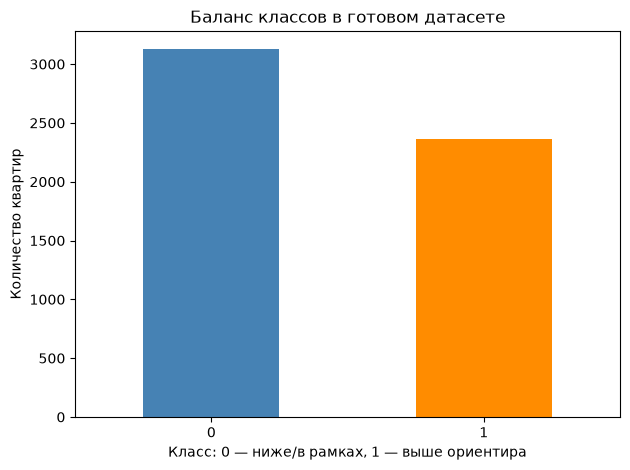

In [5]:
print("Размер рабочей таблицы:", df.shape)

class_balance = df["above_market"].value_counts().sort_index().rename("Количество").to_frame()
class_balance["Доля"] = class_balance["Количество"] / len(df)
display(class_balance)

class_balance["Количество"].plot.bar(rot=0, color=["steelblue", "darkorange"])
plt.xlabel("Класс: 0 — ниже/в рамках, 1 — выше ориентира")
plt.ylabel("Количество квартир")
plt.title("Баланс классов в готовом датасете")
plt.tight_layout()
plt.show()

<a id="features"></a>
## 5. Признаки и ответ

`X` — характеристики квартиры; `y` — правильный класс `above_market`.
Таблица уже подготовлена, поэтому отделяем только столбец ответа.

Бинарные признаки и категории после One-Hot Encoding оставим как 0/1.
Масштабируем пять количественных столбцов: площадь, этажность, этаж, комнаты и число лифтов.
Значение `rooms = 0` здесь условно трактуем как студию; специальные коды, например `-1` у лифтов, нужно уточнять у источника.

In [ ]:
X = df.drop(columns=["above_market"])
y = df["above_market"]

numeric_features = [
    "Всего этажей в доме", "Общая площадь", "Этаж",
    "rooms", "passenger_lift_count",
]
# binary_features = [column for column in X.columns if column not in numeric_features]
# assert X[binary_features].isin([0, 1]).all().all()

print("Количество признаков:", X.shape[1])
print("Масштабируем:", numeric_features)
print("Цель:", y.name)

Количество признаков: 19
Масштабируем: ['Всего этажей в доме', 'Общая площадь', 'Этаж', 'rooms', 'passenger_lift_count']
Цель: above_market


<a id="split"></a>
## 6. Делим на train и test

80% строк используем для обучения и кросс-валидации, 20% — для финальной проверки.
`stratify=y` сохраняет примерно одинаковые доли классов. `random_state` фиксирует случайное разбиение.

До финальной проверки не используем test для выбора модели или порога. Масштабирование ещё не выполнялось.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)
print("Обучающих строк:", len(X_train))
print("Тестовых строк:", len(X_test))
print("Доля класса 1 в train:", round(y_train.mean(), 3))

Обучающих строк: 4392
Тестовых строк: 1099
Доля класса 1 в train: 0.431


<a id="baseline"></a>
## 7. Простое исходное решение

`DummyClassifier(strategy="most_frequent")` всегда выдаёт самый частый **обучающий** класс.
Если большинство объектов имеют класс 0, высокая accuracy возможна даже без использования признаков.
Качество этого ориентира и модели сравним одинаковым способом.

In [8]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Класс постоянного прогноза:", baseline.predict(X_train.iloc[:1])[0])

Класс постоянного прогноза: 0


<a id="model"></a>
## 8. Логистическая регрессия: линейная сумма → вероятность → класс

### 8.1. Сначала знакомая линейная часть

$$z=b+w_1x_1+\ldots+w_px_p.$$

Это **та же форма линейной суммы, что в линейной регрессии**: признаки умножаем на веса и складываем, добавляем свободный член.
Но это ещё не весь классификатор: линейная регрессия выдаёт число напрямую, а здесь сумма `z` проходит дополнительное преобразование.
Логистическая регрессия учится по другой функции потерь.

Для примера возьмём один признак площади $x$:

$$z=-1+2x.$$

При `x = 0` получаем `z = −1`, при `x = 1` — `z = 1`.
Сумма может быть отрицательной или больше единицы, поэтому вероятностью она пока не является.

### 8.2. Сигмоида превращает сумму в P класса 1

$$P(y=1\mid x)=p=\frac{1}{1+e^{-z}}.$$

`e ≈ 2,718` — математическая константа. Подставим два результата:

- `z = −1`: $p=1/(1+e^{1})\approx0,269$;
- `z = 1`: $p=1/(1+e^{-1})\approx0,731$;
- `z = 0`: $p=1/2=0,5$.

**На пальцах:** очень отрицательная сумма даёт вероятность около 0, очень положительная — около 1.
Сигмоида плавно переводит любую линейную сумму в диапазон вероятностей.
Для порога `0,5`: `0,269 → класс 0`, `0,731 → класс 1`.
В этой бинарной модели при точном равенстве `0,5` метод `predict` выбирает класс 0.

**Функция предсказания:** линейная сумма → сигмоида → сравнение с порогом.
`predict_proba` возвращает вероятности, `predict` — классы. `fit` подбирает веса; ниже разберём, по какому правилу.


,Масштабированная площадь x,z = -1 + 2x,P(класс 1),Класс при пороге 0.5
0,-1.0,-3.0,0.047,0
1,0.0,-1.0,0.269,0
2,0.5,0.0,0.500,0
3,1.0,1.0,0.731,1
4,2.0,3.0,0.953,1


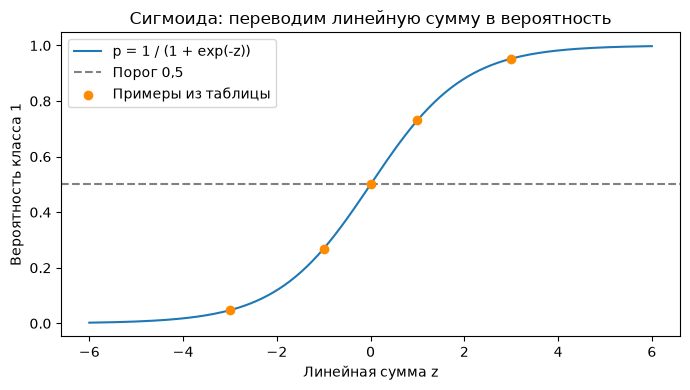

In [9]:
# Учебные веса для одного масштабированного признака.
x_demo = np.array([-1, 0, 0.5, 1, 2])
z_demo = -1 + 2 * x_demo
p_demo = 1 / (1 + np.exp(-z_demo))
display(pd.DataFrame({
    "Масштабированная площадь x": x_demo,
    "z = -1 + 2x": z_demo,
    "P(класс 1)": p_demo,
    "Класс при пороге 0.5": (p_demo > 0.5).astype(int),
}).round(3))

z_grid = np.linspace(-6, 6, 200)
plt.figure(figsize=(7, 4))
plt.plot(z_grid, 1 / (1 + np.exp(-z_grid)), label="p = 1 / (1 + exp(-z))")
plt.axhline(0.5, color="grey", linestyle="--", label="Порог 0,5")
plt.scatter(z_demo, p_demo, color="darkorange", zorder=3, label="Примеры из таблицы")
plt.xlabel("Линейная сумма z")
plt.ylabel("Вероятность класса 1")
plt.title("Сигмоида: переводим линейную сумму в вероятность")
plt.legend()
plt.tight_layout()
plt.show()

### 8.3. Функция потерь: бинарная log loss

В этой задаче **логистическая регрессия обучается по log loss**, также называемой бинарной кросс-энтропией.
У других классификаторов могут быть другие потери: это не единая обязательная функция для любой классификации.

Для одной строки:
$$\ell(y,p)=-[y\ln p+(1-y)\ln(1-p)].$$

- Если правильный класс `1`, остаётся $-\ln p$: хотим большую вероятность единицы.
- Если правильный класс `0`, остаётся $-\ln(1-p)$: хотим маленькую вероятность единицы.

`ln` — натуральный логарифм. Для понимания достаточно примеров:

| Истина y | p класса 1 | Что происходит | Потеря |
|---:|---:|---|---:|
| 1 | 0,9 | Почти уверенный верный ответ | 0,105 |
| 1 | 0,5 | Неопределённость | 0,693 |
| 1 | 0,1 | Уверенная ошибка | 2,303 |
| 0 | 0,1 | Почти уверенный верный ответ | 0,105 |
| 0 | 0,9 | Уверенная ошибка | 2,303 |

Для двух квартир с истиной `[1, 0]` и вероятностями `[0,9; 0,1]` средняя потеря:
$(-\ln0,9-\ln0,9)/2\approx0,105$.
Если поменять вероятности местами, оба ответа уверенно неверны и средняя потеря вырастет до `2,303`.

### 8.4. Что значит «обучать модель»

Для каждого объекта считаем вероятность класса 1, затем потерю log loss.
**Целевая функция обучения — средняя log loss по обучающим строкам:**

$$J(w,b)=\frac{1}{n}\sum_{i=1}^{n}\ell(y_i,p_i)\ \longrightarrow\ \min_{w,b}.$$

Здесь $n$ — число обучающих объектов, $w$ — веса признаков, $b$ — свободный член.
`fit` меняет веса и свободный член, пересчитывает вероятности и стремится уменьшить среднюю потерю.
Обучаются **параметры модели**, а не правильные ответы.
Для линейной регрессии мы минимизировали MSE; здесь — log loss.

Ниже пример: у двух объектов `x = [-1, 1]`, правильные классы `[0, 1]`, свободный член `0`.
Сравним веса `−2`, `0`, `2`. Положительный вес должен давать большую вероятность второму объекту.

,Пробный вес w,"P(1) для x=-1, истина 0","P(1) для x=1, истина 1",Средняя log loss
0,-2,0.881,0.119,2.127
1,0,0.500,0.500,0.693
2,2,0.119,0.881,0.127


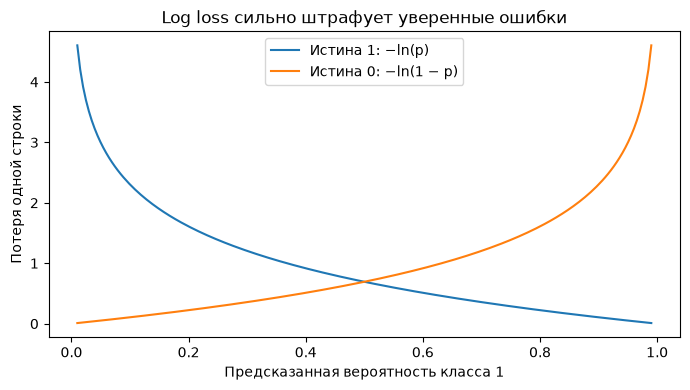

In [10]:
toy_x = np.array([-1, 1])
toy_y = np.array([0, 1])
training_steps = []
for weight in [-2, 0, 2]:
    toy_p = 1 / (1 + np.exp(-weight * toy_x))
    training_steps.append({
        "Пробный вес w": weight,
        "P(1) для x=-1, истина 0": toy_p[0],
        "P(1) для x=1, истина 1": toy_p[1],
        "Средняя log loss": log_loss(toy_y, toy_p),
    })
display(pd.DataFrame(training_steps).round(3))

p_grid = np.linspace(0.01, 0.99, 200)
plt.figure(figsize=(7, 4))
plt.plot(p_grid, -np.log(p_grid), label="Истина 1: −ln(p)")
plt.plot(p_grid, -np.log(1 - p_grid), label="Истина 0: −ln(1 − p)")
plt.xlabel("Предсказанная вероятность класса 1")
plt.ylabel("Потеря одной строки")
plt.title("Log loss сильно штрафует уверенные ошибки")
plt.legend()
plt.tight_layout()
plt.show()

### Pipeline: подготовка и модель вместе

`ColumnTransformer` масштабирует количественные признаки и пропускает бинарные без изменений.
`Pipeline` объединяет подготовку с классификатором: `fit` обучает оба шага, а `predict` применяет уже найденное преобразование.
Это защищает от вычисления статистик scaler по проверочным строкам, в том числе внутри кросс-валидации.

In [11]:
preprocessor = ColumnTransformer(
    transformers=[("numeric", StandardScaler(), numeric_features)],
    remainder="passthrough",
)
model = Pipeline([
    ("preparation", preprocessor),
    ("classifier", LogisticRegression(C=np.inf, max_iter=2000, random_state=SEED)),
])
model.fit(X_train, y_train)
print("Модель обучена. Классы:", model.classes_)

Модель обучена. Классы: [0 1]


<a id="cv"></a>
## 9. Кросс-валидация только на train

`StratifiedKFold` делит train на пять частей с близкими долями классов. На каждом шаге библиотека создаёт и обучает новую копию Pipeline.
Сравним F1 на обучающих блоках и проверочном блоке; также посмотрим accuracy и ROC-AUC.
ROC-AUC оценивает ранжирование по вероятности: 1 — идеальное ранжирование, около 0,5 — уровень случайного порядка.

Среднее описывает типичный результат, стандартное отклонение — его изменчивость между блоками. Это не доверительный интервал.

На графике после расчёта сравним F1 train и validation для каждого блока. Близкие линии означают небольшой разрыв именно в этом эксперименте; сильное падение validation относительно train потребовало бы проверки переобучения.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

cv_result = cross_validate(
    model, X_train, y_train, cv=cv, scoring=scoring,
    return_train_score=True,
)
baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)

cv_table = pd.DataFrame({
    "Блок": np.arange(1, 6),
    "F1 train": cv_result["train_f1"],
    "F1 validation": cv_result["test_f1"],
    "Accuracy validation": cv_result["test_accuracy"],
    "ROC-AUC validation": cv_result["test_roc_auc"],
})
display(cv_table.round(3))

cv_summary = pd.DataFrame([
    {"Модель": name, "Метрика": metric,
     "Среднее на проверке": result[f"test_{metric}"].mean(),
     "Std по блокам": result[f"test_{metric}"].std(ddof=0)}
    for name, result in [("Постоянный класс", baseline_cv), ("Логистическая регрессия", cv_result)]
    for metric in scoring
])
display(cv_summary.round(3))
print("Средний разрыв F1 train − validation:",
      round((cv_result["train_f1"] - cv_result["test_f1"]).mean(), 3))

,Блок,F1 train,F1 validation,Accuracy validation,ROC-AUC validation
0,1,0.876,0.860,0.879,0.952
1,2,0.873,0.877,0.895,0.952
2,3,0.874,0.860,0.882,0.950
3,4,0.872,0.858,0.880,0.955
4,5,0.866,0.887,0.901,0.959


,Модель,Метрика,Среднее на проверке,Std по блокам
0,Постоянный класс,accuracy,0.569,0.000
1,Постоянный класс,f1,0.000,0.000
2,Постоянный класс,roc_auc,0.500,0.000
3,Логистическая регрессия,accuracy,0.888,0.009
4,Логистическая регрессия,f1,0.868,0.012
5,Логистическая регрессия,roc_auc,0.954,0.003


Средний разрыв F1 train − validation: 0.004


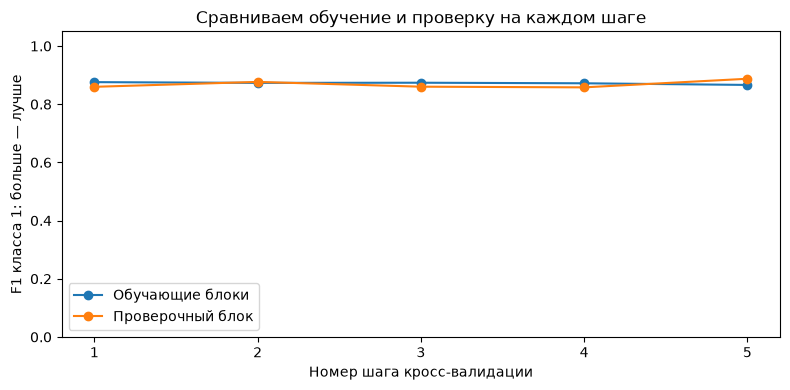

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(cv_table["Блок"], cv_table["F1 train"], "o-", label="Обучающие блоки")
plt.plot(cv_table["Блок"], cv_table["F1 validation"], "o-", label="Проверочный блок")
plt.xticks(cv_table["Блок"])
plt.ylim(0, 1.05)
plt.xlabel("Номер шага кросс-валидации")
plt.ylabel("F1 класса 1: больше — лучше")
plt.title("Сравниваем обучение и проверку на каждом шаге")
plt.legend()
plt.tight_layout()
plt.show()

модель лучше постоянного ответа? Есть ли большой разрыв train–validation?

<a id="metrics"></a>
## 10. Финальная проверка: какие ошибки делает модель

Модель и порог зафиксированы. Теперь один раз проверяем их на test.
Положительный класс — **1, выше ориентира**.

| Обозначение | Истина | Прогноз | Смысл |
|---|---:|---:|---|
| TP | 1 | 1 | Верно нашли класс 1 |
| TN | 0 | 0 | Верно нашли класс 0 |
| FP | 0 | 1 | Ложная тревога |
| FN | 1 | 0 | Пропустили класс 1 |

$$Accuracy=\frac{TP+TN}{n},\quad Precision=\frac{TP}{TP+FP},\quad Recall=\frac{TP}{TP+FN}.$$
$$F1=\frac{2\cdot Precision\cdot Recall}{Precision+Recall}.$$

Accuracy — доля всех верных ответов; precision — доля верных среди предсказанных единиц;
recall — доля найденных среди настоящих единиц. F1 соединяет precision и recall.
В коде `zero_division=0` возвращает 0, если знаменатель метрики нулевой.

In [14]:
pred = model.predict(X_test)
# Находим столбец класса 1, не полагаясь на порядок столбцов.
positive_column = list(model.classes_).index(1)
probability = model.predict_proba(X_test)[:, positive_column]
pred_baseline = baseline.predict(X_test)


def class_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (1)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (1)": recall_score(y_true, y_pred, zero_division=0),
        "F1 (1)": f1_score(y_true, y_pred, zero_division=0),
    }

results = pd.DataFrame({
    "Постоянный класс": class_metrics(y_test, pred_baseline),
    "Логистическая регрессия": class_metrics(y_test, pred),
}).T
display(results.round(3))
print("ROC-AUC модели:", round(roc_auc_score(y_test, probability), 3))
print("Log loss модели:", round(log_loss(y_test, probability), 3))

,Accuracy,Precision (1),Recall (1),F1 (1)
Постоянный класс,0.569,0.000,0.000,0.000
Логистическая регрессия,0.887,0.876,0.861,0.868


ROC-AUC модели: 0.952
Log loss модели: 0.285


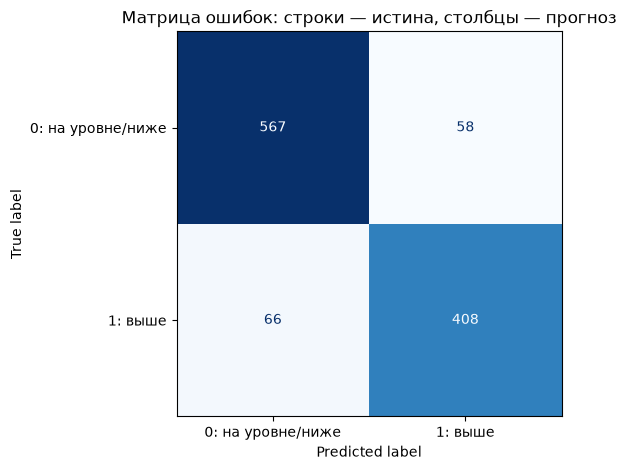

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=[0, 1],
    display_labels=["0: на уровне/ниже", "1: выше"],
    cmap="Blues", colorbar=False,
)
plt.title("Матрица ошибок: строки — истина, столбцы — прогноз")
plt.tight_layout()
plt.show()

### Log loss на финальном test

Мы уже разобрали эту функцию в разделе 8: она оценивает **вероятности**, а не только классы.
`Log loss модели` — средние потери по предсказанным вероятностям на test.
Меньшее значение лучше. Accuracy и F1 описывают другие стороны качества и могут меняться иначе.

In [16]:
# Два верных класса, но разная уверенность; затем уверенная ошибка.
probability_example = pd.DataFrame({"P(класс 1)": [0.51, 0.99, 0.01]})
probability_example["Класс при пороге 0.5"] = (
    probability_example["P(класс 1)"] > 0.5
).astype(int)
probability_example["Потеря, если истина 1"] = -np.log(probability_example["P(класс 1)"])
probability_example.round(3)

,P(класс 1),Класс при пороге 0.5,"Потеря, если истина 1"
0,0.51,1,0.673
1,0.99,1,0.010
2,0.01,0,4.605


### Смотрим отдельные прогнозы

Сравним правильные классы, вероятности и прогнозы для нескольких квартир.
Вероятность — оценка модели, а не гарантия верного ответа.

In [17]:
comparison = df.loc[X_test.index, ["Общая площадь", "rooms"]].copy()
comparison["Истинный класс"] = y_test
comparison["P(выше ориентира)"] = probability
comparison["Прогноз"] = pred
comparison["Ошибка"] = comparison["Истинный класс"] != comparison["Прогноз"]
display(comparison.head(10).round(3))
display(comparison.loc[comparison["Ошибка"]].head(5).round(3))

,Общая площадь,rooms,Истинный класс,P(выше ориентира),Прогноз,Ошибка
1678,69.0,2,0,0.035,0,False
24,55.6,2,0,0.065,0,False
3061,28.5,0,0,0.073,0,False
3525,32.1,0,1,0.957,1,False
3148,50.0,1,1,0.691,1,False
2538,65.6,2,1,0.953,1,False
3857,69.0,2,0,0.051,0,False
5,38.2,0,0,0.004,0,False
3553,59.2,2,1,0.911,1,False
5236,71.0,2,1,0.863,1,False


,Общая площадь,rooms,Истинный класс,P(выше ориентира),Прогноз,Ошибка
1890,37.0,1,0,0.795,1,True
4022,55.0,2,0,0.982,1,True
4518,92.0,3,0,0.532,1,True
1077,46.5,2,0,0.542,1,True
212,127.0,3,1,0.216,0,True


<a id="threshold"></a>
## 11. Вероятность и порог — разные вещи

Порог решения переводит вероятность в класс; веса при этом не меняются.
Снижение порога обычно позволяет найти больше настоящих единиц, но может увеличить число ложных тревог.
Precision не обязана меняться монотонно.

Ниже искусственный пример, **не подбор по test**. Порог для реальной задачи выбирают по проверочным данным внутри train с учётом цены FP и FN.

In [18]:
y_example = np.array([0, 0, 1, 0, 1, 1])
p_example = np.array([0.10, 0.35, 0.40, 0.55, 0.70, 0.90])

threshold_results = pd.DataFrame([
    {"Порог": threshold,
     **class_metrics(y_example, (p_example > threshold).astype(int))}
    for threshold in [0.3, 0.5, 0.8]
])
threshold_results.round(3)

,Порог,Accuracy,Precision (1),Recall (1),F1 (1)
0,0.3,0.667,0.600,1.000,0.750
1,0.5,0.667,0.667,0.667,0.667
2,0.8,0.667,1.000,0.333,0.500
